# Análisis exploratorio de datos (EDA) — MiBici

## 1. Objetivo

El objetivo de este notebook es explorar los datos históricos de viajes del sistema MiBici para conocer su estructura, identificar patrones de uso y analizar las principales variables del servicio.

El análisis se realizará sobre los archivos procesados durante la etapa de limpieza. Se revisarán aspectos como la cantidad de viajes registrados por mes, los horarios de mayor actividad, las diferencias entre días de la semana y las estaciones más utilizadas. También se analizará la duración de los viajes y se revisarán los datos que todavía presentan valores faltantes o situaciones que requieren atención.

Debido al tamaño del conjunto de datos, el análisis se realizará por bloques para reducir el consumo de memoria. Los archivos originales se conservarán sin modificaciones y los resultados obtenidos servirán como base para documentar los hallazgos del proyecto.

## 2. Fuente de datos

Los datos provienen del portal oficial de datos abiertos de MiBici: https://www.mibici.net/es/datos-abiertos/

Se utilizarán los archivos generados en la etapa de limpieza, ubicados en `data/processed/`. Estos archivos contienen los registros depurados de viajes, con identificadores únicos, fechas interpretables y variables adicionales para analizar la duración de los recorridos.

## 3. Alcance

El análisis contempla los registros históricos disponibles desde diciembre de 2014 hasta septiembre de 2026. Se revisarán la distribución temporal de los viajes, las características de los recorridos y el uso de las estaciones, considerando las limitaciones de calidad que se detectaron durante el diagnóstico y la limpieza.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Carpeta principal del proyecto
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# Carpeta donde están los datos limpios
DATA_DIR = PROJECT_DIR / "data" / "processed"

# Buscar los archivos CSV procesados
archivos = sorted(DATA_DIR.glob("*.csv"))

print("Carpeta del proyecto:", PROJECT_DIR)
print("Carpeta de datos:", DATA_DIR)
print("Archivos procesados encontrados:", len(archivos))

# Mostrar algunos archivos como ejemplo
for archivo in archivos[:5]:
    print(archivo.name)

Carpeta del proyecto: /Users/israperez/Documents/Maestria/Operaciones de aprendizaje automático/mibici_mlops
Carpeta de datos: /Users/israperez/Documents/Maestria/Operaciones de aprendizaje automático/mibici_mlops/data/processed
Archivos procesados encontrados: 142
datos_abiertos_2014_12.csv
datos_abiertos_2015_01.csv
datos_abiertos_2015_02.csv
datos_abiertos_2015_03.csv
datos_abiertos_2015_04.csv


## Revisar las columnas y los tipos de datos

In [2]:
# Cargar una pequeña muestra del primer archivo
df_muestra = pd.read_csv(archivos[0], nrows=5)

# Mostrar los primeros registros
display(df_muestra)

# Revisar las columnas disponibles
print("Columnas del dataset:")
print(df_muestra.columns.tolist())

# Revisar los tipos de datos
print("\nTipos de datos:")
print(df_muestra.dtypes)

# Revisar el tamaño de la muestra
print("\nFilas cargadas:", len(df_muestra))
print("Columnas encontradas:", len(df_muestra.columns))

,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,duracion_segundos,duracion_no_positiva,duracion_mayor_24h
0,4601,10324,M,NaN,2014-12-01 00:33:47,2014-12-01 00:36:54,47,47,187.0,False,False
1,4604,10324,M,NaN,2014-12-01 01:06:54,2014-12-01 01:08:45,5,5,111.0,False,False
2,4628,3,F,1990.0,2014-12-01 09:47:20,2014-12-01 09:47:47,79,79,27.0,False,False
3,4631,102,M,1982.0,2014-12-01 09:48:23,2014-12-01 09:48:37,79,79,14.0,False,False
4,4632,3,F,1990.0,2014-12-01 09:48:46,2014-12-01 09:48:57,79,79,11.0,False,False


Columnas del dataset:
['Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id', 'duracion_segundos', 'duracion_no_positiva', 'duracion_mayor_24h']

Tipos de datos:
Viaje_Id                  int64
Usuario_Id                int64
Genero                      str
Año_de_nacimiento       float64
Inicio_del_viaje            str
Fin_del_viaje               str
Origen_Id                 int64
Destino_Id                int64
duracion_segundos       float64
duracion_no_positiva       bool
duracion_mayor_24h         bool
dtype: object

Filas cargadas: 5
Columnas encontradas: 11


## Revisar la calidad y el contenido de una muestra

In [3]:
# Revisar información general de la muestra
print("Información general:")
df_muestra.info()

# Revisar valores faltantes
print("\nValores faltantes:")
print(df_muestra.isnull().sum())

# Revisar estadísticas de las variables numéricas
print("\nEstadísticas descriptivas:")
display(df_muestra.describe())

# Revisar las categorías de género de la muestra
print("\nValores de género:")
print(df_muestra["Genero"].value_counts(dropna=False))

# Revisar los indicadores de duración
print("\nViajes con duración no positiva:")
print(df_muestra["duracion_no_positiva"].value_counts(dropna=False))

print("\nViajes con duración mayor a 24 horas:")
print(df_muestra["duracion_mayor_24h"].value_counts(dropna=False))

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Viaje_Id              5 non-null      int64  
 1   Usuario_Id            5 non-null      int64  
 2   Genero                5 non-null      str    
 3   Año_de_nacimiento     3 non-null      float64
 4   Inicio_del_viaje      5 non-null      str    
 5   Fin_del_viaje         5 non-null      str    
 6   Origen_Id             5 non-null      int64  
 7   Destino_Id            5 non-null      int64  
 8   duracion_segundos     5 non-null      float64
 9   duracion_no_positiva  5 non-null      bool   
 10  duracion_mayor_24h    5 non-null      bool   
dtypes: bool(2), float64(2), int64(4), str(3)
memory usage: 697.0 bytes

Valores faltantes:
Viaje_Id                0
Usuario_Id              0
Genero                  0
Año_de_nacimiento       2
Inicio_del_viaje        0
Fin_

,Viaje_Id,Usuario_Id,Año_de_nacimiento,Origen_Id,Destino_Id,duracion_segundos
count,5.000000,5.000000,3.000000,5.000000,5.000000,5.000000
mean,4619.200000,4151.200000,1987.333333,57.800000,57.800000,70.000000
std,15.352524,5635.114613,4.618802,32.606748,32.606748,77.194559
min,4601.000000,3.000000,1982.000000,5.000000,5.000000,11.000000
25%,4604.000000,3.000000,1986.000000,47.000000,47.000000,14.000000
50%,4628.000000,102.000000,1990.000000,79.000000,79.000000,27.000000
75%,4631.000000,10324.000000,1990.000000,79.000000,79.000000,111.000000
max,4632.000000,10324.000000,1990.000000,79.000000,79.000000,187.000000



Valores de género:
Genero
M    3
F    2
Name: count, dtype: int64

Viajes con duración no positiva:
duracion_no_positiva
False    5
Name: count, dtype: int64

Viajes con duración mayor a 24 horas:
duracion_mayor_24h
False    5
Name: count, dtype: int64


## Analizar la cantidad de viajes por mes

In [4]:
import re

viajes_por_mes = []

for archivo in archivos:
    # Buscar año y mes en el nombre del archivo
    coincidencia = re.search(r"(\d{4})_(\d{2})", archivo.stem)

    if coincidencia is None:
        print("Nombre de archivo no reconocido:", archivo.name)
        continue

    anio_mes = coincidencia.group(0)

    total_viajes = 0

    # Leer el archivo por bloques
    for bloque in pd.read_csv(
        archivo,
        usecols=["Viaje_Id"],
        chunksize=100_000
    ):
        total_viajes += len(bloque)

    viajes_por_mes.append({
        "Mes": anio_mes,
        "Total_viajes": total_viajes
    })

# Crear y ordenar la tabla
df_viajes_mes = pd.DataFrame(viajes_por_mes)

df_viajes_mes["Mes"] = pd.to_datetime(
    df_viajes_mes["Mes"],
    format="%Y_%m"
)

df_viajes_mes = df_viajes_mes.sort_values("Mes").reset_index(drop=True)

print("Primeros meses:")
display(df_viajes_mes.head())

print("Últimos meses:")
display(df_viajes_mes.tail())

print("Total de viajes contabilizados:", df_viajes_mes["Total_viajes"].sum())
print("Cantidad de meses:", len(df_viajes_mes))

Primeros meses:


,Mes,Total_viajes
0,2014-12-01,23967
1,2015-01-01,32144
2,2015-02-01,32787
3,2015-03-01,36096
4,2015-04-01,34863


Últimos meses:


,Mes,Total_viajes
137,2026-05-01,315895
138,2026-06-01,355303
139,2026-07-01,388257
140,2026-08-01,393524
141,2026-09-01,489298


Total de viajes contabilizados: 39078226
Cantidad de meses: 142


## Graficar la evolución mensual de los viajes

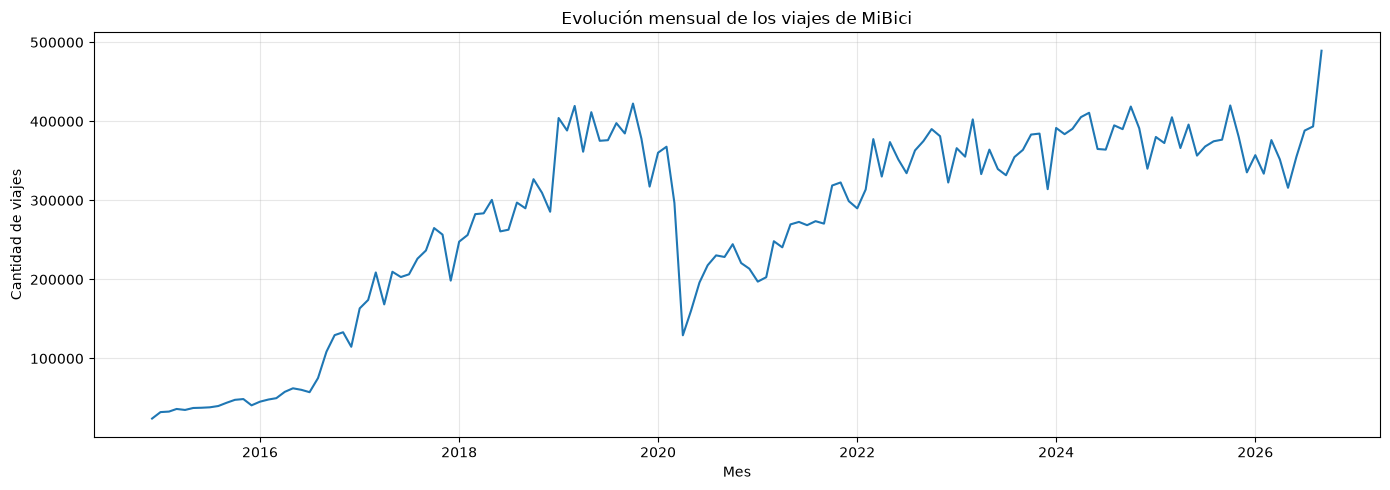

In [5]:
plt.figure(figsize=(14, 5))

plt.plot(
    df_viajes_mes["Mes"],
    df_viajes_mes["Total_viajes"]
)

plt.title("Evolución mensual de los viajes de MiBici")
plt.xlabel("Mes")
plt.ylabel("Cantidad de viajes")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Viajes por año

,Anio,Total_viajes
0,2014,23967
1,2015,469871
2,2016,941918
3,2017,2516534
4,2018,3403485
5,2019,4636652
6,2020,2866072
7,2021,3184410
8,2022,4202942
9,2023,4293115


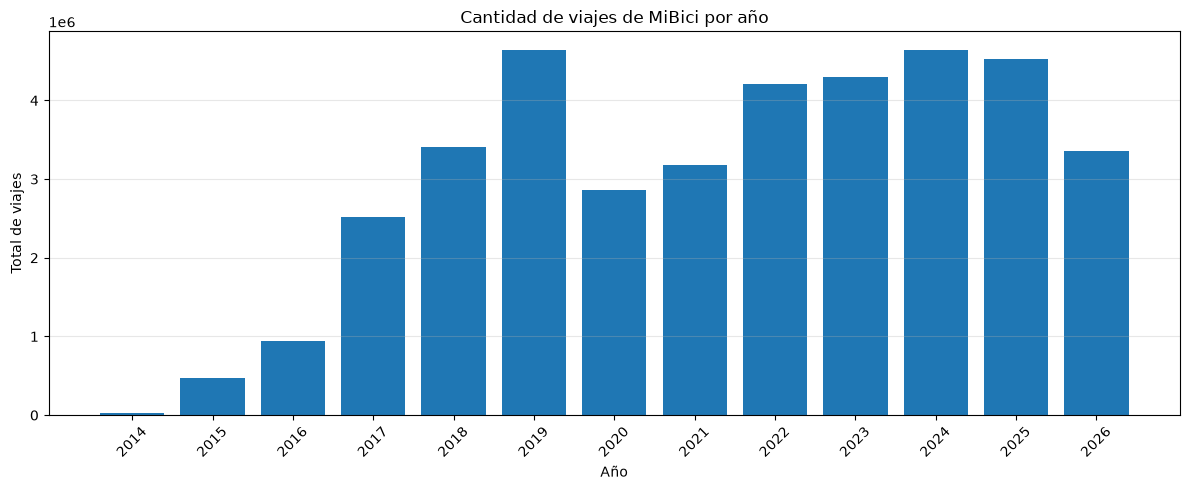

In [6]:
# Agrupar los viajes por año
df_viajes_anio = (
    df_viajes_mes
    .groupby(df_viajes_mes["Mes"].dt.year)["Total_viajes"]
    .sum()
    .reset_index()
)

df_viajes_anio.columns = ["Anio", "Total_viajes"]

# Mostrar los resultados
display(df_viajes_anio)

# Graficar la evolución anual
plt.figure(figsize=(12, 5))

plt.bar(
    df_viajes_anio["Anio"].astype(str),
    df_viajes_anio["Total_viajes"]
)

plt.title("Cantidad de viajes de MiBici por año")
plt.xlabel("Año")
plt.ylabel("Total de viajes")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación de la evolución histórica

La cantidad de viajes registrados por MiBici muestra un crecimiento importante durante los años anteriores a la pandemia. Entre 2016 y 2019, el total anual pasó de aproximadamente 942 mil a 4.64 millones de viajes. Esto refleja un aumento considerable en el uso registrado del sistema, aunque para entenderlo mejor también será necesario considerar la evolución de la infraestructura y la cobertura de los datos.

En 2020 se observa una caída importante, con cerca de 2.87 millones de viajes, alrededor de un 38 % menos que en 2019. Esta disminución coincide con el periodo de la pandemia de COVID-19, por lo que resulta relevante investigarla como posible factor relacionado con el cambio. Sin embargo, estos datos por sí solos no permiten afirmar que la pandemia explique toda la reducción.

A partir de 2021 se observa una recuperación. En 2022 el sistema registró nuevamente más de cuatro millones de viajes y los totales se mantuvieron por encima de ese nivel durante 2023, 2024 y 2025. En 2025 se aprecia una ligera reducción respecto al año anterior, que conviene revisar junto con los cambios en la cobertura de los registros y el número de estaciones.

Por último, 2014 y 2026 son periodos incompletos dentro de este conjunto de datos: 2014 solo incluye diciembre y 2026 llega hasta septiembre. Por esta razón, sus totales no deben compararse directamente con los de años completos.


## Calcular los cambios porcentuales por año

In [7]:
# Calcular el cambio porcentual respecto al año anterior
df_viajes_anio["Cambio_porcentual"] = (
    df_viajes_anio["Total_viajes"].pct_change() * 100
).round(2)

display(df_viajes_anio)

,Anio,Total_viajes,Cambio_porcentual
0,2014,23967,NaN
1,2015,469871,1860.49
2,2016,941918,100.46
3,2017,2516534,167.17
4,2018,3403485,35.24
5,2019,4636652,36.23
6,2020,2866072,-38.19
7,2021,3184410,11.11
8,2022,4202942,31.98
9,2023,4293115,2.15


### Variación porcentual anual

El cambio porcentual permite comparar la evolución de los viajes respecto al año anterior y dimensionar mejor los aumentos y las caídas. Entre 2017 y 2019 se mantuvo una tendencia de crecimiento, aunque el porcentaje de aumento fue menor en 2018 que en 2017.

La variación más importante de los años recientes se presenta en 2020, cuando los viajes disminuyeron un 38.19 % respecto a 2019. En 2021 comenzó una recuperación, con un aumento del 11.11 %, que se hizo más evidente en 2022, cuando los viajes crecieron un 31.98 %. Estos cambios coinciden con el periodo de la pandemia y la recuperación posterior, pero se requiere más información para establecer qué factores explican las variaciones.

En 2023 el crecimiento fue más moderado, con un 2.15 %, mientras que en 2024 aumentó un 8.22 %. En 2025 se registró una disminución del 2.45 % respecto al año anterior. Este último cambio puede investigarse junto con la evolución de las estaciones y la calidad de los registros para determinar si refleja una variación en el uso del sistema o si existen otros factores que considerar.

_**Nota.** Los porcentajes de 2015 y 2026 deben interpretarse con precaución, ya que se calculan comparando años con distinta cobertura temporal. Por esta razón, no son indicadores adecuados para evaluar por sí solos el crecimiento o la disminución anual._

## evolución de las estaciones

In [8]:
# Buscar archivos que podrían contener el catálogo de estaciones
archivos_estaciones = [
    archivo
    for archivo in PROJECT_DIR.rglob("*.csv")
    if "estacion" in archivo.name.lower()
    or "nomenclatura" in archivo.name.lower()
]

for archivo in archivos_estaciones:
    print(archivo)

/Users/israperez/Documents/Maestria/Operaciones de aprendizaje automático/mibici_mlops/data/raw/nomenclatura_2026_09.csv


## Inspeccionar el catálogo de estaciones

In [9]:
# Cargar el catálogo de estaciones
archivo_estaciones = archivos_estaciones[0]
df_estaciones = pd.read_csv(archivo_estaciones)

# Revisar dimensiones y columnas
print("Filas:", len(df_estaciones))
print("Columnas:", len(df_estaciones.columns))
print("\nColumnas disponibles:")
print(df_estaciones.columns.tolist())

# Mostrar los primeros registros
display(df_estaciones.head())

# Revisar valores faltantes
print("\nValores faltantes:")
print(df_estaciones.isnull().sum())

# Revisar identificadores duplicados
print("\nIdentificadores duplicados:")
print(df_estaciones["id"].duplicated().sum())

Filas: 484
Columnas: 5

Columnas disponibles:
['id', 'name', 'latitude', 'longitude', 'dpcapacity']


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11



Valores faltantes:
id            0
name          0
latitude      0
longitude     0
dpcapacity    0
dtype: int64

Identificadores duplicados:
0


## Calcular un resumen del inventario actual

In [10]:
# Resumen del catálogo de estaciones
print("Número de estaciones:", len(df_estaciones))
print("Capacidad total registrada:", df_estaciones["dpcapacity"].sum())
print(
    "Capacidad promedio por estación:",
    round(df_estaciones["dpcapacity"].mean(), 2)
)
print(
    "Capacidad mínima:",
    df_estaciones["dpcapacity"].min()
)
print(
    "Capacidad máxima:",
    df_estaciones["dpcapacity"].max()
)

Número de estaciones: 484
Capacidad total registrada: 8171
Capacidad promedio por estación: 16.88
Capacidad mínima: 0
Capacidad máxima: 39


### Resultados del inventario de estaciones

El catálogo de septiembre de 2026 contiene 484 estaciones y registra una capacidad acumulada de 8,171 espacios. La capacidad promedio es de aproximadamente 16.88 espacios por estación, con valores que van de 0 a 39.

Aunque el catálogo no presenta valores faltantes ni identificadores duplicados, la capacidad mínima de cero requiere una revisión adicional. Este valor podría representar una condición particular del inventario o un dato que necesita validación; por sí solo, no permite concluir que exista un error.

Estos resultados describen el catálogo analizado y no deben interpretarse como una reconstrucción del crecimiento histórico de la red. Para determinar cuántas estaciones existían en años anteriores, se necesitan inventarios históricos o registros que permitan identificar las fechas de incorporación y baja de las estaciones.


## Revisar las estaciones con capacidad cero

In [11]:
# Revisar estaciones con capacidad igual a cero
estaciones_cero = df_estaciones[
    df_estaciones["dpcapacity"] == 0
]

print("Estaciones con capacidad cero:", len(estaciones_cero))

display(estaciones_cero)

Estaciones con capacidad cero: 4


,id,name,latitude,longitude,dpcapacity
94,99,ex-(ZPN-009) C. Del Corral / C. Nicolás Bravo,20.685108,-103.333746,0
104,109,ex-(ZPN-019) C. Cabecera Mpal. Juan Manuel / C.,20.723221,-103.385583,0
111,116,ex-(ZPN-026) C. 16 Sep. / C. Fray A. de Segovia,20.686920,-103.334670,0
129,138,ex-(ZPN-044),20.697050,-103.363220,0


### Revisión de estaciones con capacidad cero

Se identificaron cuatro registros de estaciones con capacidad igual a cero. En los cuatro casos, los nombres incluyen el prefijo `ex-`, lo que podría estar relacionado con estaciones anteriores o fuera de operación. Sin embargo, el catálogo por sí solo no permite confirmar su estado operativo ni la fecha en que dejaron de funcionar.

Por esta razón, no se eliminaron estos registros ni se consideraron automáticamente errores. Se conservarán como parte del inventario y se documentarán como casos que requieren validación. Esta revisión también muestra por qué el número de registros del catálogo no debe interpretarse directamente como el número de estaciones activas.


## calidad de los datos por año

In [12]:
# Variables que revisaremos en cada año
columnas_calidad = [
    "Viaje_Id",
    "Genero",
    "Año_de_nacimiento",
    "Inicio_del_viaje",
    "duracion_no_positiva",
    "duracion_mayor_24h"
]

resultados_calidad = []

for archivo in archivos:
    # Obtener el año del archivo
    import re

    coincidencia = re.search(r"(\d{4})_(\d{2})", archivo.stem)

    if coincidencia is None:
        continue

    anio_archivo = int(coincidencia.group(1))

    # Contadores del archivo
    total = 0
    genero_faltante = 0
    nacimiento_faltante = 0
    duracion_no_positiva = 0
    duracion_mayor_24h = 0

    # Leer por bloques
    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_calidad,
        chunksize=100_000
    ):
        total += len(bloque)
        genero_faltante += bloque["Genero"].isna().sum()
        nacimiento_faltante += bloque["Año_de_nacimiento"].isna().sum()
        duracion_no_positiva += bloque["duracion_no_positiva"].sum()
        duracion_mayor_24h += bloque["duracion_mayor_24h"].sum()

    resultados_calidad.append({
        "Anio": anio_archivo,
        "Total_viajes": total,
        "Genero_faltante": genero_faltante,
        "Nacimiento_faltante": nacimiento_faltante,
        "Duracion_no_positiva": duracion_no_positiva,
        "Duracion_mayor_24h": duracion_mayor_24h
    })

# Sumar los archivos mensuales de cada año
df_calidad_anio = (
    pd.DataFrame(resultados_calidad)
    .groupby("Anio", as_index=False)
    .sum()
    .sort_values("Anio")
)

display(df_calidad_anio)

,Anio,Total_viajes,Genero_faltante,Nacimiento_faltante,Duracion_no_positiva,Duracion_mayor_24h
0,2014,23967,5,220,0,2
1,2015,469871,236,3765,0,16
2,2016,941918,207,7150,0,410
3,2017,2516534,0,12794,2,1045
4,2018,3403485,0,11981,1,70
5,2019,4636652,6415,11922,0,130
6,2020,2866072,3349,3930,1728,80
7,2021,3184410,4832,4918,2906,33
8,2022,4202942,18154,16172,5792,4
9,2023,4293115,19621,6877,17945,12


Algunas observaciones iniciales:
- Género faltante: aumenta de manera notable a partir de 2022 y alcanza su mayor cantidad en 2025.
- Año de nacimiento faltante: presenta cantidades elevadas en los primeros años y vuelve a aumentar en 2022; después disminuye considerablemente.
- Duraciones no positivas: aparecen con mayor frecuencia a partir de 2020, con un máximo de 20,850 registros en 2024.
- Duraciones mayores a 24 horas: destacan especialmente en 2016 y 2017, con 410 y 1,045 registros, respectivamente.

## Calcular porcentajes de problemas por año

In [13]:
# Crear una copia para conservar la tabla original
df_calidad_porcentaje = df_calidad_anio.copy()

# Calcular el porcentaje de cada problema por año
columnas_problemas = {
    "Genero_faltante": "Pct_genero_faltante",
    "Nacimiento_faltante": "Pct_nacimiento_faltante",
    "Duracion_no_positiva": "Pct_duracion_no_positiva",
    "Duracion_mayor_24h": "Pct_duracion_mayor_24h"
}

for columna, nueva_columna in columnas_problemas.items():
    df_calidad_porcentaje[nueva_columna] = (
        df_calidad_porcentaje[columna]
        / df_calidad_porcentaje["Total_viajes"]
        * 100
    ).round(3)

# Mostrar los porcentajes
display(
    df_calidad_porcentaje[
        ["Anio", "Pct_genero_faltante",
         "Pct_nacimiento_faltante", "Pct_duracion_no_positiva",
         "Pct_duracion_mayor_24h"]
    ]
)

,Anio,Pct_genero_faltante,Pct_nacimiento_faltante,Pct_duracion_no_positiva,Pct_duracion_mayor_24h
0,2014,0.021,0.918,0.000,0.008
1,2015,0.050,0.801,0.000,0.003
2,2016,0.022,0.759,0.000,0.044
3,2017,0.000,0.508,0.000,0.042
4,2018,0.000,0.352,0.000,0.002
5,2019,0.138,0.257,0.000,0.003
6,2020,0.117,0.137,0.060,0.003
7,2021,0.152,0.154,0.091,0.001
8,2022,0.432,0.385,0.138,0.000
9,2023,0.457,0.160,0.418,0.000


## Visualizar los problemas de calidad por año

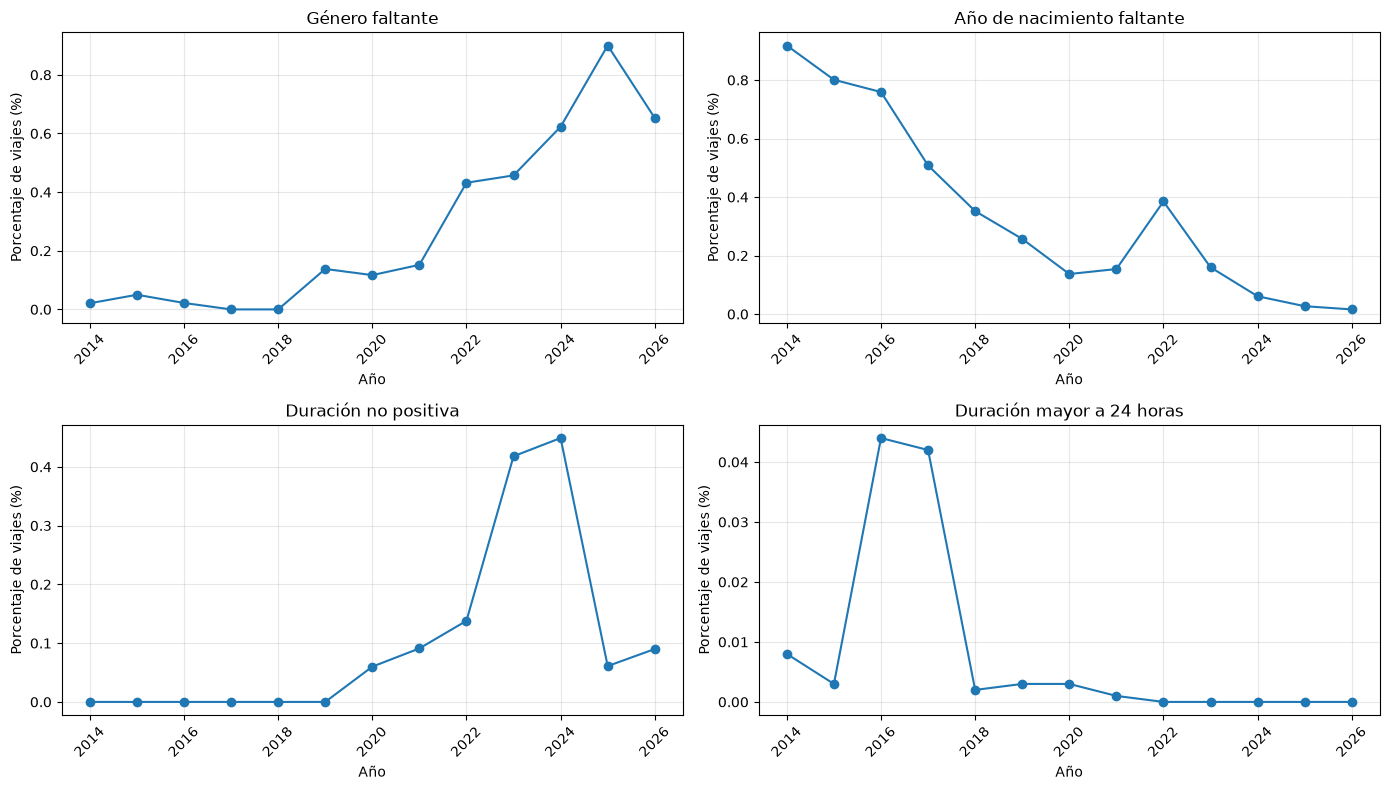

In [14]:
columnas_porcentaje = [
    "Pct_genero_faltante",
    "Pct_nacimiento_faltante",
    "Pct_duracion_no_positiva",
    "Pct_duracion_mayor_24h"
]

titulos = [
    "Género faltante",
    "Año de nacimiento faltante",
    "Duración no positiva",
    "Duración mayor a 24 horas"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, columna, titulo in zip(
    axes.flatten(), columnas_porcentaje, titulos
):
    ax.plot(
        df_calidad_porcentaje["Anio"],
        df_calidad_porcentaje[columna],
        marker="o"
    )
    ax.set_title(titulo)
    ax.set_xlabel("Año")
    ax.set_ylabel("Porcentaje de viajes (%)")
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Evolución de los problemas de calidad de los datos

Las gráficas permiten observar cómo cambian los problemas de calidad a lo largo del tiempo. El porcentaje de viajes sin género aumenta principalmente a partir de 2022, mientras que los registros sin año de nacimiento muestran una tendencia general a la baja. Por otro lado, las duraciones no positivas comienzan a aparecer en 2020 y presentan sus porcentajes más altos entre 2022 y 2024. Las duraciones mayores a 24 horas tienen una presencia reducida y destacan principalmente en 2016 y 2017.

Esta comparación ayuda a identificar los periodos que podrían necesitar una revisión más detallada. Sin embargo, los datos no permiten determinar por sí solos las causas de estos cambios. Además, 2014 y 2026 son periodos incompletos, por lo que deben interpretarse considerando que no representan años con doce meses de información.

En conclusión, revisar los porcentajes por año complementa el conteo de registros problemáticos y permite distinguir entre problemas que disminuyen con el tiempo y otros que se vuelven más frecuentes en periodos recientes.


## Uso de estaciones

### Análisis de estaciones

En esta sección se analiza el uso de las estaciones a partir de los viajes registrados. El objetivo es identificar cuáles estaciones concentran más salidas y llegadas, y observar si existen diferencias en su nivel de uso. También se considera el catálogo de estaciones disponible para septiembre de 2026, teniendo en cuenta que no necesariamente representa la configuración de la red en años anteriores.

Es importante distinguir entre el número de viajes asociados a una estación y el número de estaciones disponibles en cada año. Con los registros de viajes podemos estudiar el uso histórico, pero para conocer con precisión cuándo se incorporaron o retiraron estaciones necesitaríamos catálogos históricos.


In [15]:
columnas_estaciones = ["Origen_Id", "Destino_Id"]

conteo_estaciones = {}

for archivo in archivos:
    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_estaciones,
        chunksize=100_000
    ):
        for columna in columnas_estaciones:
            conteo = bloque[columna].value_counts()
            if columna not in conteo_estaciones:
                conteo_estaciones[columna] = conteo
            else:
                conteo_estaciones[columna] = (
                    conteo_estaciones[columna]
                    .add(conteo, fill_value=0)
                )

salidas = conteo_estaciones["Origen_Id"].sort_values(
    ascending=False
)
llegadas = conteo_estaciones["Destino_Id"].sort_values(
    ascending=False
)

print("Estaciones con más salidas:")
display(salidas.head(10))

print("Estaciones con más llegadas:")
display(llegadas.head(10))

Estaciones con más salidas:


Origen_Id
51     840156.0
11     601475.0
50     589305.0
52     565178.0
35     562985.0
54     508270.0
271    476314.0
194    418005.0
75     410587.0
58     365518.0
Name: count, dtype: float64

Estaciones con más llegadas:


Destino_Id
51     1080850.0
35      639226.0
50      617820.0
11      558166.0
52      556004.0
54      549272.0
34      460298.0
271     452924.0
58      426213.0
56      419179.0
Name: count, dtype: float64

Interpretación de los resultados
- La estación 51 destaca claramente: registra 840,156 salidas y 1,080,850 llegadas. Además de ser la estación con más salidas, es la que acumula más llegadas entre todas las estaciones.
- Las estaciones 11, 50, 52, 35 y 54 también aparecen entre las diez con más salidas y llegadas, lo que indica que concentran bastante actividad en ambos sentidos.
- La estación 271 también destaca, con 476,314 salidas y 452,924 llegadas.
- Hay diferencias entre salidas y llegadas. Por ejemplo, la estación 51 tiene bastantes más llegadas que salidas, mientras que la estación 11 tiene más salidas que llegadas. Esto podría reflejar patrones de desplazamiento, pero no permite determinar por sí solo por qué ocurre.
Como estos conteos cubren varios años, una estación pudo haber tenido más tiempo para acumular viajes que otra. Tampoco podemos asegurar que los identificadores correspondan a estaciones activas actualmente.

## Identificar los nombres de las estaciones

In [16]:
# Juntar las estaciones con más salidas y llegadas
df_top_estaciones = pd.DataFrame({
    "Salidas": salidas,
    "Llegadas": llegadas
}).fillna(0)

# Agregar los nombres del catálogo
df_top_estaciones = df_top_estaciones.merge(
    df_estaciones[["id", "name"]],
    left_index=True,
    right_on="id",
    how="left"
)

# Calcular el total de movimientos registrados
df_top_estaciones["Total_movimientos"] = (
    df_top_estaciones["Salidas"]
    + df_top_estaciones["Llegadas"]
)

# Mostrar las 10 estaciones con más movimientos
df_top_estaciones = df_top_estaciones.sort_values(
    "Total_movimientos",
    ascending=False
)

display(
    df_top_estaciones[
        ["id", "name", "Salidas", "Llegadas", "Total_movimientos"]
    ].head(10)
)

,id,name,Salidas,Llegadas,Total_movimientos
48.0,51,(GDL-049) Lopez Cotilla / Penitenciaría,840156.0,1080850.0,1921006.0
47.0,50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,589305.0,617820.0,1207125.0
32.0,35,(GDL-033) Av. Hidalgo / C. Pedro Loza,562985.0,639226.0,1202211.0
8.0,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,601475.0,558166.0,1159641.0
49.0,52,(GDL-050) C.Pedro Moreno /Federalismo,565178.0,556004.0,1121182.0
51.0,54,(GDL-052) Av. Juarez /16 de Septiembre,508270.0,549272.0,1057542.0
260.0,271,(GDL-198) Av. Alcalde / C. Hospital,476314.0,452924.0,929238.0
31.0,34,(GDL-032) C. Degollado / Av. Miguel Hidalgo,351552.0,460298.0,811850.0
72.0,75,(GDL-073) Av. La Paz / Av. Federalismo,410587.0,397298.0,807885.0
55.0,58,(GDL-056) Av. 16 de Sept. / C. Miguel Blanco,365518.0,426213.0,791731.0


## Graficar las 10 estaciones con más actividad

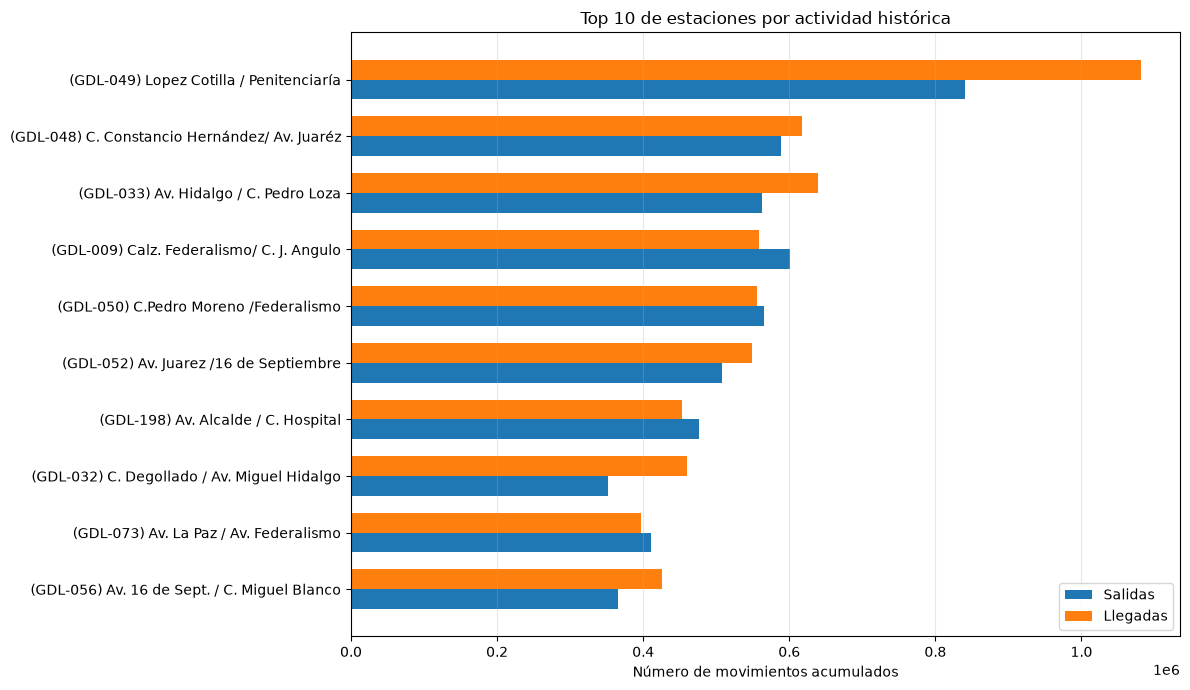

In [17]:
# Seleccionar las 10 estaciones con más movimientos
top_10 = df_top_estaciones.head(10).sort_values(
    "Total_movimientos",
    ascending=True
)

# Crear la gráfica
fig, ax = plt.subplots(figsize=(12, 7))

posiciones = range(len(top_10))
altura = 0.35

ax.barh(
    [p - altura / 2 for p in posiciones],
    top_10["Salidas"],
    height=altura,
    label="Salidas"
)

ax.barh(
    [p + altura / 2 for p in posiciones],
    top_10["Llegadas"],
    height=altura,
    label="Llegadas"
)

ax.set_yticks(list(posiciones))
ax.set_yticklabels(top_10["name"])
ax.set_xlabel("Número de movimientos acumulados")
ax.set_title("Top 10 de estaciones por actividad histórica")
ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Estaciones con mayor actividad histórica

La comparación entre salidas y llegadas muestra que López Cotilla / Penitenciaría (ID 51) destaca por encima del resto, especialmente por la cantidad de llegadas registradas. Otras estaciones, como Constancio Hernández / Av. Juárez (ID 50) y Av. Hidalgo / C. Pedro Loza (ID 35), también presentan una actividad acumulada elevada.

Las diferencias entre salidas y llegadas permiten identificar estaciones en las que se registran más viajes iniciados o finalizados. Sin embargo, estos resultados abarcan todo el periodo disponible y no representan necesariamente el comportamiento actual. Además, el análisis no permite determinar las causas de las diferencias ni reconstruir por sí solo la evolución histórica de la red de estaciones.


## Viajes por mes

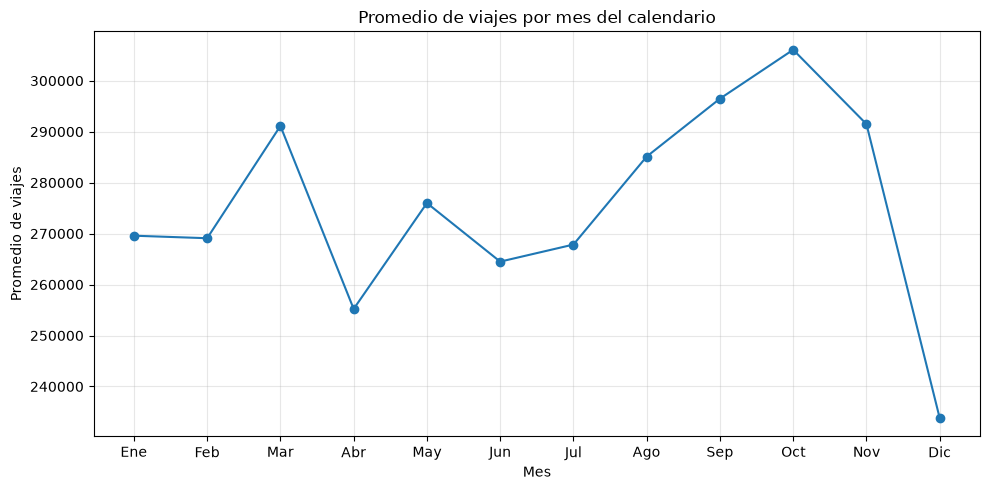

,Promedio_viajes
Mes_numero,
10,306074.0
9,296476.0
11,291483.0
3,291128.0
8,285115.0
5,275993.0
1,269588.0
2,269092.0
7,267848.0


In [18]:
# Obtener el promedio de viajes para cada mes del año
df_viajes_mes["Mes_numero"] = df_viajes_mes["Mes"].dt.month

viajes_por_mes_calendario = (
    df_viajes_mes
    .groupby("Mes_numero")["Total_viajes"]
    .mean()
)

# Graficar el promedio mensual
plt.figure(figsize=(10, 5))

plt.plot(
    viajes_por_mes_calendario.index,
    viajes_por_mes_calendario.values,
    marker="o"
)

plt.xticks(
    range(1, 13),
    ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
     "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
)

plt.xlabel("Mes")
plt.ylabel("Promedio de viajes")
plt.title("Promedio de viajes por mes del calendario")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(
    viajes_por_mes_calendario
    .sort_values(ascending=False)
    .rename("Promedio_viajes")
    .round(0)
    .to_frame()
)

### Comportamiento de los viajes según el mes

Al comparar el promedio de viajes por mes del calendario, octubre presenta el valor más alto, con aproximadamente 306 mil viajes, seguido de septiembre y noviembre. Por otro lado, diciembre registra el promedio más bajo, con cerca de 234 mil viajes.

Estos resultados sugieren que la actividad del sistema puede variar según el mes. Sin embargo, es necesario interpretar esta diferencia con precaución, ya que el análisis combina años con distintos niveles de uso y diciembre incluye el primer mes disponible, que corresponde únicamente a una parte del mes de diciembre de 2014. Esta observación puede reducir el promedio de ese mes.

Por lo tanto, los resultados permiten identificar diferencias mensuales, pero no son suficientes para confirmar que exista un patrón estacional constante. Para comprobarlo con mayor precisión sería conveniente comparar los mismos meses entre años completos y considerar otros factores, como los cambios en la red de estaciones.


## Estimar cuántas estaciones se utilizaron cada año

In [19]:
estaciones_por_anio = []

for archivo in archivos:
    coincidencia = re.search(r"(\d{4})_(\d{2})", archivo.stem)

    if coincidencia is None:
        continue

    anio = int(coincidencia.group(1))
    estaciones = set()

    for bloque in pd.read_csv(
        archivo,
        usecols=["Origen_Id", "Destino_Id"],
        chunksize=100_000
    ):
        estaciones.update(bloque["Origen_Id"].dropna().unique())
        estaciones.update(bloque["Destino_Id"].dropna().unique())

    estaciones_por_anio.append({
        "Anio": anio,
        "Estaciones_con_viajes": len(estaciones)
    })

df_estaciones_anio = pd.DataFrame(estaciones_por_anio)

df_estaciones_anio = (
    df_estaciones_anio
    .groupby("Anio")["Estaciones_con_viajes"]
    .sum()
    .reset_index()
)

display(df_estaciones_anio)

,Anio,Estaciones_con_viajes
0,2014,86
1,2015,1262
2,2016,1998
3,2017,2824
4,2018,2903
5,2019,3289
6,2020,3290
7,2021,3498
8,2022,3600
9,2023,3736


La tabla muestra una tendencia creciente, pero hay un detalle importante: los valores actuales no representan estaciones únicas por año. El código anterior sumó los conteos de cada mes, por lo que una estación que aparece durante varios meses se cuenta repetidamente. No debemos interpretar esos valores como cantidad de estaciones activas.

### Corregir el cálculo

In [20]:
estaciones_por_anio = []

for anio in sorted(
    set(
        int(re.search(r"(\d{4})_(\d{2})", archivo.stem).group(1))
        for archivo in archivos
        if re.search(r"(\d{4})_(\d{2})", archivo.stem)
    )
):
    archivos_anio = [
        archivo for archivo in archivos
        if re.search(r"(\d{4})_(\d{2})", archivo.stem)
        and int(re.search(r"(\d{4})_(\d{2})", archivo.stem).group(1)) == anio
    ]

    estaciones = set()

    for archivo in archivos_anio:
        for bloque in pd.read_csv(
            archivo,
            usecols=["Origen_Id", "Destino_Id"],
            chunksize=100_000
        ):
            estaciones.update(bloque["Origen_Id"].dropna().unique())
            estaciones.update(bloque["Destino_Id"].dropna().unique())

    estaciones_por_anio.append({
        "Anio": anio,
        "Estaciones_distintas_con_viajes": len(estaciones)
    })

df_estaciones_anio = pd.DataFrame(estaciones_por_anio)

display(df_estaciones_anio)

,Anio,Estaciones_distintas_con_viajes
0,2014,86
1,2015,116
2,2016,241
3,2017,239
4,2018,278
5,2019,275
6,2020,276
7,2021,300
8,2022,300
9,2023,359


### Graficar la evolución de las estaciones

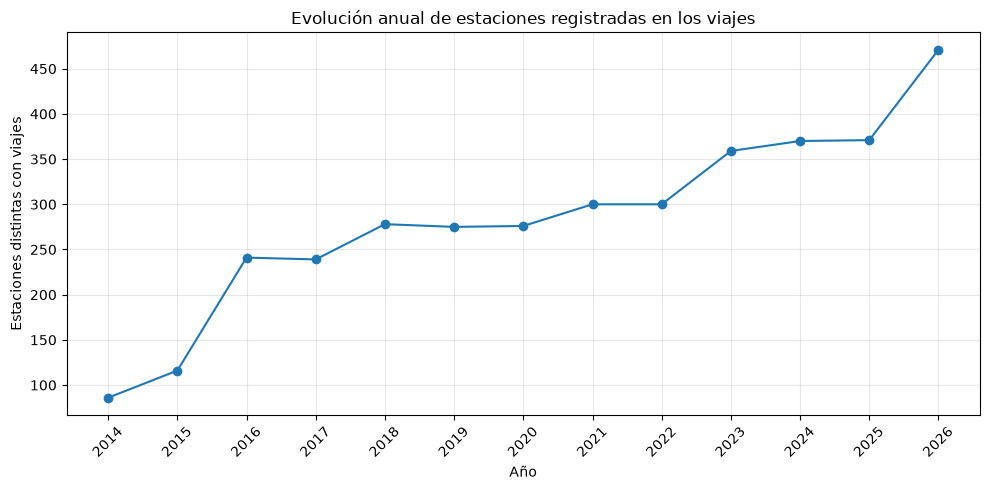

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    df_estaciones_anio["Anio"],
    df_estaciones_anio["Estaciones_distintas_con_viajes"],
    marker="o"
)

plt.xlabel("Año")
plt.ylabel("Estaciones distintas con viajes")
plt.title("Evolución anual de estaciones registradas en los viajes")
plt.xticks(df_estaciones_anio["Anio"], rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Evolución de las estaciones con actividad registrada

El análisis muestra un crecimiento general en la cantidad de estaciones distintas que aparecen en los registros de viajes. En diciembre de 2014 se identificaron 86 estaciones, mientras que en 2025 se registraron 371. Entre 2019 y 2022 los valores se mantuvieron relativamente estables, seguidos por un aumento en 2023.

Para 2026 se identificaron 471 estaciones distintas. Este resultado destaca frente a los años anteriores y conviene revisarlo con mayor detalle para confirmar si refleja cambios en la cobertura del sistema, incorporaciones de estaciones o diferencias en los registros.

Este indicador permite describir la evolución de las estaciones utilizadas en los viajes, pero no equivale al inventario oficial de estaciones disponibles en cada año. Además, 2014 solo incluye diciembre y 2026 contiene información hasta septiembre, por lo que ambos años deben interpretarse considerando su cobertura parcial.


### Comparar los identificadores de estaciones

In [22]:
# Obtener los archivos correspondientes a 2026
archivos_2026 = [
    archivo for archivo in archivos
    if re.search(r"2026_(\d{2})", archivo.stem)
]

# Reunir los identificadores que aparecen en los viajes de 2026
estaciones_2026 = set()

for archivo in archivos_2026:
    for bloque in pd.read_csv(
        archivo,
        usecols=["Origen_Id", "Destino_Id"],
        chunksize=100_000
    ):
        estaciones_2026.update(bloque["Origen_Id"].dropna().unique())
        estaciones_2026.update(bloque["Destino_Id"].dropna().unique())

# Obtener los identificadores del catálogo actual
estaciones_catalogo = set(df_estaciones["id"].dropna().unique())

# Comparar ambos conjuntos
en_viajes_no_catalogo = estaciones_2026 - estaciones_catalogo
en_catalogo_sin_viajes = estaciones_catalogo - estaciones_2026
en_ambos = estaciones_2026 & estaciones_catalogo

print("Estaciones distintas en viajes de 2026:", len(estaciones_2026))
print("Estaciones del catálogo:", len(estaciones_catalogo))
print("Identificadores presentes en ambos:", len(en_ambos))
print("En viajes, pero no en catálogo:", len(en_viajes_no_catalogo))
print("En catálogo, pero sin viajes en 2026:", len(en_catalogo_sin_viajes))

Estaciones distintas en viajes de 2026: 471
Estaciones del catálogo: 484
Identificadores presentes en ambos: 469
En viajes, pero no en catálogo: 2
En catálogo, pero sin viajes en 2026: 15


### Revisar los identificadores que no coinciden

In [23]:
print("En viajes de 2026, pero no en el catálogo:")
print(sorted(en_viajes_no_catalogo))

print("\nEn el catálogo, pero sin viajes registrados en 2026:")
print(sorted(en_catalogo_sin_viajes))

En viajes de 2026, pero no en el catálogo:
[np.int64(405), np.int64(407)]

En el catálogo, pero sin viajes registrados en 2026:
[np.int64(22), np.int64(97), np.int64(99), np.int64(109), np.int64(113), np.int64(114), np.int64(116), np.int64(138), np.int64(147), np.int64(149), np.int64(223), np.int64(240), np.int64(250), np.int64(310), np.int64(492)]


### Validación de estaciones contra el catálogo de 2026

Se compararon los identificadores de las estaciones presentes en los viajes de enero a septiembre de 2026 con el catálogo disponible para septiembre del mismo año. De las 471 estaciones distintas identificadas en los viajes, 469 también aparecen en el catálogo, lo que representa una coincidencia aproximada del 99.6%.

Se encontraron dos identificadores, 405 y 407, que aparecen en los viajes, pero no en el catálogo. Además, 15 identificadores del catálogo no aparecen en los viajes de 2026. Estas diferencias pueden deberse a cambios entre versiones, estaciones que ya no forman parte de la red o estaciones que no registraron actividad durante el periodo analizado; sin embargo, los datos disponibles no permiten confirmar ninguna de estas causas.

En general, la comparación muestra una alta coincidencia entre los identificadores de los viajes y el catálogo. Aun así, las diferencias encontradas deben conservarse como observaciones para una posible revisión, sin asumir automáticamente que representan errores en los datos.


## Conclusiones generales del análisis exploratorio

Durante este análisis exploramos el historial de viajes de MiBici desde diciembre de 2014 hasta septiembre de 2026. En total, el conjunto procesado contiene aproximadamente 39.08 millones de viajes, lo que permite observar cómo ha cambiado el uso del sistema a lo largo del tiempo e identificar algunos aspectos que requieren atención en la calidad de los datos.

En cuanto a la actividad anual, observamos un crecimiento importante durante los primeros años, hasta alcanzar aproximadamente 4.64 millones de viajes en 2019. En 2020, el número de viajes disminuyó cerca de un 38% respecto al año anterior. Después se observa una recuperación, con más de cuatro millones de viajes anuales entre 2022 y 2025. Esta caída coincide con el periodo de la pandemia de COVID-19, aunque los datos analizados por sí solos no permiten establecer que esa sea la única causa del cambio.

El análisis de calidad mostró que los problemas varían según el año y el tipo de dato. Los registros sin género aumentan en los años recientes, mientras que los valores faltantes de año de nacimiento disminuyen después de aplicar las reglas de limpieza. También encontramos duraciones iguales o menores que cero y viajes que superan las 24 horas. En lugar de eliminar automáticamente estos viajes, se conservaron indicadores que permiten identificarlos y analizarlos posteriormente. Esto ayuda a mantener información potencialmente útil sin ocultar las inconsistencias detectadas.

Al analizar las estaciones, encontramos que López Cotilla / Penitenciaría, identificada con el ID 51, destaca por su cantidad acumulada de salidas y llegadas. También observamos diferencias entre los meses: octubre presenta el mayor promedio de viajes, mientras que diciembre registra el menor. Estos resultados sugieren diferencias en la actividad del sistema, pero sería necesario realizar comparaciones adicionales entre años completos para confirmar si existe un patrón estacional consistente.

La cantidad de estaciones distintas que aparecen en los viajes también aumenta a lo largo del periodo analizado. Sin embargo, este indicador representa estaciones con actividad registrada y no necesariamente el número oficial de estaciones disponibles en cada año. Al comparar los identificadores de los viajes de 2026 con el catálogo de septiembre de ese año, encontramos una coincidencia aproximada del 99.6%. Las diferencias identificadas quedaron documentadas para una posible revisión, sin clasificarlas automáticamente como errores.

En general, este EDA permitió conocer mejor el tamaño y la evolución del conjunto de datos, detectar problemas de calidad y reconocer patrones en el uso de las estaciones. También permitió identificar limitaciones importantes, como la falta de catálogos históricos de estaciones y la cobertura parcial de 2014 y 2026. Estos hallazgos sirven como base para las siguientes etapas del proyecto, ya que ayudan a decidir qué información requiere mayor validación y qué variables pueden utilizarse con más confianza en análisis posteriores.
